# 03 — Survival: time-to-churn

> **Data sources:** Cell2Cell telecom churn (`jpacse/datasets-for-churn-telecom`, Kaggle mirror of the Teradata/Duke data) and the Hillstrom MineThatData e-mail experiment (minethatdata.com). **Downloaded:** 2026-08-10. Run `make data` to reproduce `data/raw/`.

Whether a customer churns is one question; *when* is another. Kaplan-Meier gives the retention curve, Cox the hazard ratios.

In [1]:
from churn_uplift.data import CHURN_TARGET, DURATION_COL, load_cell2cell
from churn_uplift.evaluation import plots
from churn_uplift.models import (
    cox_model,
    hazard_ratios,
    kaplan_meier,
    kaplan_meier_by_group,
)

df = load_cell2cell()
dur, ev = df[DURATION_COL].to_numpy(), df[CHURN_TARGET].to_numpy()
kmf = kaplan_meier(dur, ev)
print("median survival (months):", kmf.median_survival_time_)

median survival (months): 34.0


## Retention curve by usage intensity

Heavy users retain longer than light users.

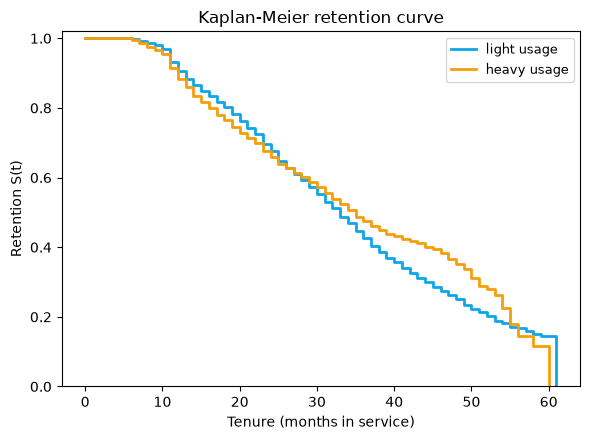

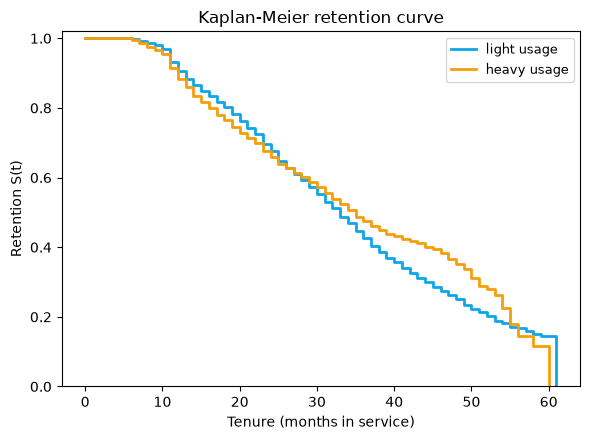

In [2]:
heavy = (df["MonthlyMinutes"] > df["MonthlyMinutes"].median()).map(
    {True: "heavy usage", False: "light usage"}
)
plots.plot_km(kaplan_meier_by_group(dur, ev, heavy.to_numpy()))

## Cox hazard ratios

HR > 1 multiplies the instantaneous churn risk.

In [3]:
cov = [
    "MonthlyRevenue",
    "MonthlyMinutes",
    "CustomerCareCalls",
    "DroppedCalls",
    "OverageMinutes",
]
cox = cox_model(df, duration_col=DURATION_COL, event_col=CHURN_TARGET, covariates=cov)
hazard_ratios(cox)[["hazard_ratio", "p", "direction"]].round(4)

,hazard_ratio,p,direction
covariate,,,
CustomerCareCalls,1.0081,0.0000,increases churn
DroppedCalls,1.0053,0.0000,increases churn
OverageMinutes,1.0006,0.0000,increases churn
MonthlyMinutes,0.9999,0.0000,reduces churn
MonthlyRevenue,0.9990,0.0018,reduces churn
